# Feast feature store: online (RDS Postgres) + offline (S3 parquet)

- **Online store** - Feast RDS Postgres (`sde-airflow-dev-feast-pg`).
- **Offline store** - parquet under `s3://<ml-bucket>/features/instacart/offline/`.
- **Feature Marketplace** - the Feast registry, indexed and searchable.
- **EDA** + an **advanced data-science lab** (model eval/explainability, PCA/clustering, recommendations, consistency, quality).

## How to run
`make feast-notebook` (starts the tunnel + JupyterLab). Local kernels: see `notebooks/README.md`.


In [20]:
# Ensure the kernel has the Feast Postgres extra + offline deps (no-op in the container).
try:
    import psycopg2  # noqa: F401
    import s3fs  # noqa: F401
    import feast  # noqa: F401
except ImportError:
    %pip install -q "feast[postgres]>=0.40,<0.70" psycopg2-binary "dask[dataframe]" s3fs pyarrow pandas boto3


In [1]:
!pip install pandoc
import os, sys, subprocess, tempfile
from pathlib import Path

os.environ.setdefault("AWS_DEFAULT_REGION", "us-east-2")
REGION = os.environ["AWS_DEFAULT_REGION"]

# Locate the repo root so we can import feast_repo/.
root = Path.cwd()
while root != root.parent and not (root / "feast_repo").exists():
    root = root.parent
sys.path.insert(0, str(root / "feast_repo"))

def tf_output(name, default=None):
    try:
        return subprocess.check_output(["terraform", f"-chdir={root / 'terraform'}", "output", "-raw", name], text=True).strip()
    except Exception:
        return default

BUCKET = os.environ.get("ML_S3_BUCKET") or tf_output("ml_s3_bucket")
OFFLINE_S3 = f"s3://{BUCKET}/features/instacart/offline/features.parquet"

os.environ.setdefault("FEAST_DB_HOST", "localhost")
os.environ.setdefault("FEAST_DB_PORT", os.environ.get("FEAST_LOCAL_PORT", "15432"))
os.environ.setdefault("FEAST_DB_NAME", "feast")
os.environ.setdefault("FEAST_DB_USER", "feast")
os.environ.setdefault("FEAST_DB_SSLMODE", "prefer")
os.environ.setdefault("FEAST_REGISTRY", "/tmp/feast_notebook/registry.db")

if not os.environ.get("FEAST_DB_PASSWORD"):
    import boto3
    os.environ["FEAST_DB_PASSWORD"] = boto3.client("ssm", region_name=REGION).get_parameter(
        Name="/sde-airflow/dev/feast/db-password", WithDecryption=True)["Parameter"]["Value"]

import boto3, pandas as pd
LOCAL_OFFLINE = "/tmp/feast_offline/features.parquet"
if not Path(LOCAL_OFFLINE).exists():
    Path(LOCAL_OFFLINE).parent.mkdir(parents=True, exist_ok=True)
    key = OFFLINE_S3.split(f"s3://{BUCKET}/", 1)[1]
    print("downloading", OFFLINE_S3)
    boto3.client("s3", region_name=REGION).download_file(BUCKET, key, LOCAL_OFFLINE)
os.environ["FEAST_OFFLINE_PATH"] = LOCAL_OFFLINE

# Loaded here so EDA/offline sections work even if the online DB is unreachable.
offline_df = pd.read_parquet(LOCAL_OFFLINE)
print("offline rows:", len(offline_df))
print("bucket :", BUCKET)
print("online :", os.environ["FEAST_DB_HOST"], os.environ["FEAST_DB_PORT"], "db=" + os.environ["FEAST_DB_NAME"])
print("offline:", OFFLINE_S3)


  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 kB 3.4 MB/s eta 0:00:00
  Created wheel for pandoc: filename=pandoc-2.4-py3-none-any.whl size=34872 sha256=80c0ecab2e67c40c78968408df264f604b377f5ac04d32a7b1442e5b3e0785b9
  Stored in directory: /root/.cache/pip/wheels/4f/d7/32/c6c9b7b05e852e920fd72174487be3a0f18e633a7adcc303be
Successfully built pandoc

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
downloading s3://sde-airflow-dev-ml-559540498216/features/instacart/offline/features.parquet
offline rows: 87731
bucket : sde-airflow-dev-ml-559540498216
online : host.docker.internal 15432 db=feast
offline: s3://sde-airflow-dev-ml-559540498216/features/instacart/offline/features.parquet


In [22]:
import feast_config, features
from feast import FeatureStore

REPO = tempfile.mkdtemp(prefix="feast_notebook_")
feast_config.write_feature_store_yaml(REPO)
store = FeatureStore(repo_path=REPO)
try:
    store.apply([features.user, features.product, features.user_product_reorder_features])
    print("feature views:", [fv.name for fv in store.list_feature_views()])
    print("entities     :", [e.name for e in store.list_entities()])
except Exception as exc:
    print("WARNING: could not register with the online store (is the tunnel up? run `make feast-tunnel`):", exc)


feature views: ['user_product_reorder_features']
entities     : ['user', 'product']


## Online store (RDS Postgres)

Fast key-value lookup for `(user_id, product_id)` pairs - what `/predict_online` uses.


In [23]:
pairs = offline_df[["user_id", "product_id"]].drop_duplicates().head(5).to_dict("records")
print("entity rows:", pairs)

feast_cols = [f"user_product_reorder_features:{c}" for c in feast_config.FEATURE_COLUMNS]
online = None
try:
    resp = store.get_online_features(features=feast_cols, entity_rows=pairs)
    online = resp.to_df() if hasattr(resp, "to_df") else pd.DataFrame(resp.to_dict())
except Exception as exc:
    print("WARNING: online lookup failed (is the tunnel up? run `make feast-tunnel`):", exc)
online


entity rows: [{'user_id': 1, 'product_id': 196}, {'user_id': 1, 'product_id': 10258}, {'user_id': 1, 'product_id': 10326}, {'user_id': 1, 'product_id': 12427}, {'user_id': 1, 'product_id': 13032}]


,user_id,product_id,user_avg_days_between_orders,days_since_last_purchase,reorder_rate,times_bought,times_bought_per_order,avg_add_to_cart,max_add_to_cart,product_order_count,product_avg_add_to_cart,user_reorder_rate,min_add_to_cart,department_id,aisle_id,user_total_orders,product_reorder_rate
0,1,196,19.555555,0.0,0.900000,10.0,1.0,1.400000,4.0,6041.0,3.697567,0.694915,1.0,7.0,77.0,10.0,0.784638
1,1,10258,19.555555,0.0,0.888889,9.0,0.9,3.333333,6.0,159.0,3.377358,0.694915,2.0,19.0,117.0,10.0,0.773585
2,1,10326,19.555555,5.0,0.000000,1.0,0.1,5.000000,5.0,273.0,4.102564,0.694915,5.0,4.0,24.0,10.0,0.622711
3,1,12427,19.555555,0.0,0.900000,10.0,1.0,3.300000,9.0,342.0,5.561403,0.694915,1.0,19.0,23.0,10.0,0.719298
4,1,13032,19.555555,0.0,0.666667,3.0,0.3,6.333333,8.0,257.0,6.435798,0.694915,5.0,14.0,121.0,10.0,0.649805


In [24]:
import psycopg2
try:
    conn = psycopg2.connect(
        host=os.environ["FEAST_DB_HOST"], port=int(os.environ["FEAST_DB_PORT"]),
        dbname=os.environ["FEAST_DB_NAME"], user=os.environ["FEAST_DB_USER"],
        password=os.environ["FEAST_DB_PASSWORD"], sslmode=os.environ["FEAST_DB_SSLMODE"],
        connect_timeout=10)
    tables = pd.read_sql("select table_name from information_schema.tables where table_schema='public' order by 1", conn)
    print("online tables:")
    print(tables.to_string(index=False))
    candidates = [t for t in tables.table_name if "reorder" in t] or list(tables.table_name)
    if candidates:
        tbl = candidates[0]
        print("table =", tbl, "| rows =", int(pd.read_sql('select count(*) c from "%s"' % tbl, conn).iloc[0, 0]))
        from IPython.display import display
        display(pd.read_sql('select * from "%s" limit 10' % tbl, conn))
    conn.close()
except Exception as exc:
    print("WARNING: could not query the online store (is the tunnel up?):", exc)


/tmp/ipykernel_356/1544333594.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  tables = pd.read_sql("select table_name from information_schema.tables where table_schema='public' order by 1", conn)
/tmp/ipykernel_356/1544333594.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  print("table =", tbl, "| rows =", int(pd.read_sql('select count(*) c from "%s"' % tbl, conn).iloc[0, 0]))


online tables:
                             table_name
instacart_user_product_reorder_features
table = instacart_user_product_reorder_features | rows = 14468610


/tmp/ipykernel_356/1544333594.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  display(pd.read_sql('select * from "%s" limit 10' % tbl, conn))


,entity_key,feature_name,value,value_text,vector_value,event_ts,created_ts
0,"[b'\x02', b'\x00', b'\x00', b'\x00', b'\x02', ...",times_bought,"[b'5', b'\x00', b'\x00', b'\x80', b'?']",None,None,2026-10-06 01:19:02.092229+00:00,None
1,"[b'\x02', b'\x00', b'\x00', b'\x00', b'\x02', ...",reorder_rate,"[b'5', b'\x00', b'\x00', b'\x00', b'\x00']",None,None,2026-10-06 01:19:02.092229+00:00,None
2,"[b'\x02', b'\x00', b'\x00', b'\x00', b'\x02', ...",avg_add_to_cart,"[b'5', b'\x00', b'\x00', b'\x80', b'@']",None,None,2026-10-06 01:19:02.092229+00:00,None
3,"[b'\x02', b'\x00', b'\x00', b'\x00', b'\x02', ...",min_add_to_cart,"[b'5', b'\x00', b'\x00', b'\x80', b'@']",None,None,2026-10-06 01:19:02.092229+00:00,None
4,"[b'\x02', b'\x00', b'\x00', b'\x00', b'\x02', ...",max_add_to_cart,"[b'5', b'\x00', b'\x00', b'\x80', b'@']",None,None,2026-10-06 01:19:02.092229+00:00,None
5,"[b'\x02', b'\x00', b'\x00', b'\x00', b'\x02', ...",user_total_orders,"[b'5', b'\x00', b'\x00', b'\x0c', b'B']",None,None,2026-10-06 01:19:02.092229+00:00,None
6,"[b'\x02', b'\x00', b'\x00', b'\x00', b'\x02', ...",user_avg_days_between_orders,"[b'5', b'\x1e', b'\x1e', b'\x1e', b'A']",None,None,2026-10-06 01:19:02.092229+00:00,None
7,"[b'\x02', b'\x00', b'\x00', b'\x00', b'\x02', ...",user_reorder_rate,"[b'5', b'\x80', b'\x99', b'B', b'?']",None,None,2026-10-06 01:19:02.092229+00:00,None
8,"[b'\x02', b'\x00', b'\x00', b'\x00', b'\x02', ...",times_bought_per_order,"[b'5', b'\xa1', b'\x0e', b'\xea', b'<']",None,None,2026-10-06 01:19:02.092229+00:00,None
9,"[b'\x02', b'\x00', b'\x00', b'\x00', b'\x02', ...",days_since_last_purchase,"[b'5', b'\x00', b'\x00', b' ', b'A']",None,None,2026-10-06 01:19:02.092229+00:00,None


## Offline store (S3 parquet)

Full feature history - read directly and via Feast point-in-time retrieval.


In [25]:
print("offline path :", OFFLINE_S3)
print("shape        :", offline_df.shape)
print("columns      :", list(offline_df.columns))
offline_df.head()


offline path : s3://sde-airflow-dev-ml-559540498216/features/instacart/offline/features.parquet
shape        : (852334, 19)
columns      : ['user_id', 'product_id', 'event_timestamp', 'times_bought', 'reorder_rate', 'avg_add_to_cart', 'min_add_to_cart', 'max_add_to_cart', 'user_total_orders', 'user_avg_days_between_orders', 'user_reorder_rate', 'times_bought_per_order', 'days_since_last_purchase', 'product_reorder_rate', 'product_order_count', 'product_avg_add_to_cart', 'department_id', 'aisle_id', 'label']


,user_id,product_id,event_timestamp,times_bought,reorder_rate,avg_add_to_cart,min_add_to_cart,max_add_to_cart,user_total_orders,user_avg_days_between_orders,user_reorder_rate,times_bought_per_order,days_since_last_purchase,product_reorder_rate,product_order_count,product_avg_add_to_cart,department_id,aisle_id,label
0,1,196,2026-10-05 17:22:15.765495+00:00,10.0,0.900000,1.400000,1.0,4.0,10.0,19.555555,0.694915,1.0,0.0,0.773080,2318.0,3.583693,7.0,77.0,1
1,1,10258,2026-10-05 17:22:15.765495+00:00,9.0,0.888889,3.333333,2.0,6.0,10.0,19.555555,0.694915,0.9,0.0,0.773585,159.0,3.377358,19.0,117.0,1
2,1,10326,2026-10-05 17:22:15.765495+00:00,1.0,0.000000,5.000000,5.0,5.0,10.0,19.555555,0.694915,0.1,5.0,0.622711,273.0,4.102564,4.0,24.0,0
3,1,12427,2026-10-05 17:22:15.765495+00:00,10.0,0.900000,3.300000,1.0,9.0,10.0,19.555555,0.694915,1.0,0.0,0.719298,342.0,5.561403,19.0,23.0,0
4,1,13032,2026-10-05 17:22:15.765495+00:00,3.0,0.666667,6.333333,5.0,8.0,10.0,19.555555,0.694915,0.3,0.0,0.649805,257.0,6.435798,14.0,121.0,1


In [26]:
from datetime import datetime, timezone
entity_df = pd.DataFrame({
    "user_id": [p["user_id"] for p in pairs],
    "product_id": [p["product_id"] for p in pairs],
    "event_timestamp": [datetime.now(timezone.utc)] * len(pairs),
})
hist = store.get_historical_features(entity_df=entity_df, features=feast_cols).to_df()
hist


,user_id,product_id,event_timestamp,times_bought,reorder_rate,avg_add_to_cart,min_add_to_cart,max_add_to_cart,user_total_orders,user_avg_days_between_orders,user_reorder_rate,times_bought_per_order,days_since_last_purchase,product_reorder_rate,product_order_count,product_avg_add_to_cart,department_id,aisle_id
0,1,196,2026-10-06 01:29:56.545995+00:00,10.0,0.900000,1.400000,1.0,4.0,10.0,19.555555,0.694915,1.0,0.0,0.773080,2318.0,3.583693,7.0,77.0
1,1,10258,2026-10-06 01:29:56.545995+00:00,9.0,0.888889,3.333333,2.0,6.0,10.0,19.555555,0.694915,0.9,0.0,0.773585,159.0,3.377358,19.0,117.0
2,1,10326,2026-10-06 01:29:56.545995+00:00,1.0,0.000000,5.000000,5.0,5.0,10.0,19.555555,0.694915,0.1,5.0,0.622711,273.0,4.102564,4.0,24.0
3,1,12427,2026-10-06 01:29:56.545995+00:00,10.0,0.900000,3.300000,1.0,9.0,10.0,19.555555,0.694915,1.0,0.0,0.719298,342.0,5.561403,19.0,23.0
4,1,13032,2026-10-06 01:29:56.545995+00:00,3.0,0.666667,6.333333,5.0,8.0,10.0,19.555555,0.694915,0.3,0.0,0.649805,257.0,6.435798,14.0,121.0


## Summary


In [27]:
print("ONLINE  (RDS Postgres) :", os.environ["FEAST_DB_HOST"], os.environ["FEAST_DB_PORT"], "db=" + os.environ["FEAST_DB_NAME"])
print("        features       :", "n/a (tunnel down?)" if online is None else online.shape)
print("OFFLINE (S3 parquet)   :", OFFLINE_S3)
print("        rows           :", offline_df.shape[0])


ONLINE  (RDS Postgres) : host.docker.internal 15432 db=feast
        features       : (5, 17)
OFFLINE (S3 parquet)   : s3://sde-airflow-dev-ml-559540498216/features/instacart/offline/features.parquet
        rows           : 852334


## Feature Marketplace - search, index & explore the registry

The Feast registry is the feature marketplace: every applied entity/feature view/feature/data source/service is discoverable here.


In [28]:
def _join_keys(fv):
    cols = getattr(fv, "entity_columns", None) or []
    return [getattr(c, "name", str(c)) for c in cols]

def _fv_rows(fv):
    ents = _join_keys(fv)
    src = getattr(fv, "batch_source", None)
    ttl = getattr(fv, "ttl", None)
    for f in getattr(fv, "features", []):
        yield {
            "feature_view": fv.name,
            "feature": f.name,
            "dtype": str(getattr(f, "dtype", "")),
            "entities": ",".join(map(str, ents)),
            "source": getattr(src, "name", "") if src else "",
            "source_path": getattr(src, "path", "") if src else "",
            "ttl_days": getattr(ttl, "days", None),
            "online": bool(getattr(fv, "online", False)),
        }

marketplace = pd.DataFrame([row for fv in store.list_feature_views() for row in _fv_rows(fv)])
print("indexed %d features across %d feature view(s)" % (len(marketplace), marketplace.feature_view.nunique()))
marketplace


indexed 15 features across 1 feature view(s)


,feature_view,feature,dtype,entities,source,source_path,ttl_days,online
0,user_product_reorder_features,times_bought,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
1,user_product_reorder_features,reorder_rate,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
2,user_product_reorder_features,avg_add_to_cart,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
3,user_product_reorder_features,min_add_to_cart,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
4,user_product_reorder_features,max_add_to_cart,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
5,user_product_reorder_features,user_total_orders,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
6,user_product_reorder_features,user_avg_days_between_orders,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
7,user_product_reorder_features,user_reorder_rate,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
8,user_product_reorder_features,times_bought_per_order,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
9,user_product_reorder_features,days_since_last_purchase,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True


In [29]:
def search_features(query):
    q = query.strip().lower()
    mask = marketplace.apply(lambda s: s.astype(str).str.lower().str.contains(q, na=False))
    return marketplace[mask.any(axis=1)].reset_index(drop=True)

search_features("reorder")


,feature_view,feature,dtype,entities,source,source_path,ttl_days,online
0,user_product_reorder_features,times_bought,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
1,user_product_reorder_features,reorder_rate,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
2,user_product_reorder_features,avg_add_to_cart,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
3,user_product_reorder_features,min_add_to_cart,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
4,user_product_reorder_features,max_add_to_cart,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
5,user_product_reorder_features,user_total_orders,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
6,user_product_reorder_features,user_avg_days_between_orders,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
7,user_product_reorder_features,user_reorder_rate,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
8,user_product_reorder_features,times_bought_per_order,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True
9,user_product_reorder_features,days_since_last_purchase,Float32,"user_id,product_id",instacart_offline,/tmp/feast_offline/features.parquet,3650,True


In [30]:
print("Feature views   :", [fv.name for fv in store.list_feature_views()])
print("Entities        :", [e.name for e in store.list_entities()])
print("Data sources    :", [d.name for d in store.list_data_sources()])
print("Feature services:", [fs.name for fs in store.list_feature_services()])


Feature views   : ['user_product_reorder_features']
Entities        : ['user', 'product']
Data sources    : ['instacart_offline']
Feature services: []


In [31]:
fv = store.get_feature_view("user_product_reorder_features")
print("name         :", fv.name, "| project:", getattr(fv, "project", ""))
print("entities     :", fv.entities)
print("join keys    :", _join_keys(fv))
print("ttl          :", fv.ttl, "| online:", getattr(fv, "online", None))
src = getattr(fv, "batch_source", None)
print("batch source :", getattr(src, "name", ""), "->", getattr(src, "path", ""))
print("features:")
for f in fv.features:
    print("  - %-32s %s" % (f.name, f.dtype))


name         : user_product_reorder_features | project: 
entities     : ['user', 'product']
join keys    : ['user_id', 'product_id']
ttl          : 3650 days, 0:00:00 | online: True
batch source : instacart_offline -> /tmp/feast_offline/features.parquet
features:
  - times_bought                     Float32
  - reorder_rate                     Float32
  - avg_add_to_cart                  Float32
  - min_add_to_cart                  Float32
  - max_add_to_cart                  Float32
  - user_total_orders                Float32
  - user_avg_days_between_orders     Float32
  - user_reorder_rate                Float32
  - times_bought_per_order           Float32
  - days_since_last_purchase         Float32
  - product_reorder_rate             Float32
  - product_order_count              Float32
  - product_avg_add_to_cart          Float32
  - department_id                    Float32
  - aisle_id                         Float32


## Exploratory Data Analysis


In [32]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")
FEATS = feast_config.FEATURE_COLUMNS
eda = offline_df.copy()
print("rows:", len(eda), "| columns:", eda.shape[1])
print("unique users   :", eda.user_id.nunique())
print("unique products:", eda.product_id.nunique())
print("candidates/user: %.1f" % (len(eda) / eda.user_id.nunique()))
miss = eda.isnull().sum()
print("missing values :", "none" if not (miss > 0).any() else dict(miss[miss > 0]))


/usr/local/lib/python3.11/site-packages/matplotlib/_fontconfig_pattern.py:64: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  prop = Group((name + Suppress("=") + comma_separated(value)) | oneOf(_CONSTANTS))
/usr/local/lib/python3.11/site-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.11/site-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.11/site-packages/matplotlib/_mathtext.py:45: PyparsingDeprecationWarning: 'enablePackrat' deprecated - use 'enable_packrat'
  ParserElement.enablePackrat()
In /usr/local/lib/python3.11/site-packages/matplotlib/mpl-data/stylelib/classic.mplstyle: 'parseString' deprecated - use 'parse_string'
In /usr/local/lib/python3.11/site-packages/matplotlib/mpl-data/stylelib/classic.mplstyle: 'reset

rows: 852334 | columns: 19
unique users   : 13120
unique products: 37673
candidates/user: 65.0
missing values : none


In [33]:
eda[FEATS].describe().T


,count,mean,std,min,25%,50%,75%,max
times_bought,852334.0,2.448181,3.592331,1.000000,1.000000,1.000000,2.000000,90.000000
reorder_rate,852334.0,0.265838,0.339969,0.000000,0.000000,0.000000,0.500000,0.988889
avg_add_to_cart,852334.0,9.237335,7.091030,1.000000,4.000000,7.500000,12.000000,122.000000
min_add_to_cart,852334.0,7.696750,7.147872,1.000000,2.000000,6.000000,11.000000,122.000000
max_add_to_cart,852334.0,11.153342,8.393509,1.000000,5.000000,9.000000,15.000000,137.000000
user_total_orders,852334.0,25.444939,22.272827,3.000000,9.000000,18.000000,35.000000,99.000000
user_avg_days_between_orders,852334.0,12.620391,6.440127,0.000000,7.500000,11.433333,16.777779,30.000000
user_reorder_rate,852334.0,0.501848,0.198213,0.000000,0.358209,0.517241,0.657895,0.978723
times_bought_per_order,852334.0,0.153645,0.163902,0.010101,0.045455,0.095238,0.200000,1.000000
days_since_last_purchase,852334.0,9.567402,13.465736,0.000000,1.000000,4.000000,12.000000,98.000000


label
0    0.902565
1    0.097435


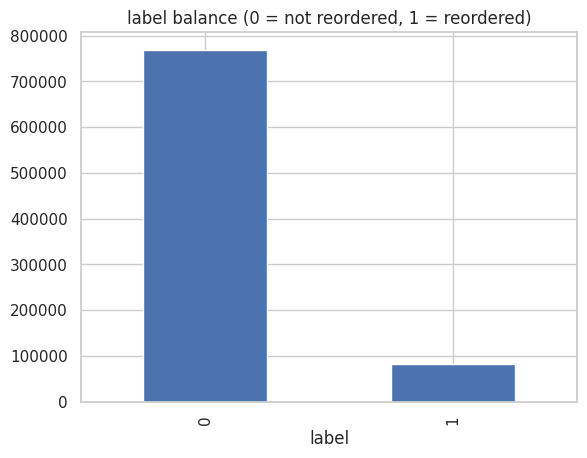

In [34]:
print(eda["label"].value_counts(normalize=True).rename("share").to_string())
eda["label"].value_counts().sort_index().plot.bar(title="label balance (0 = not reordered, 1 = reordered)")
plt.show()


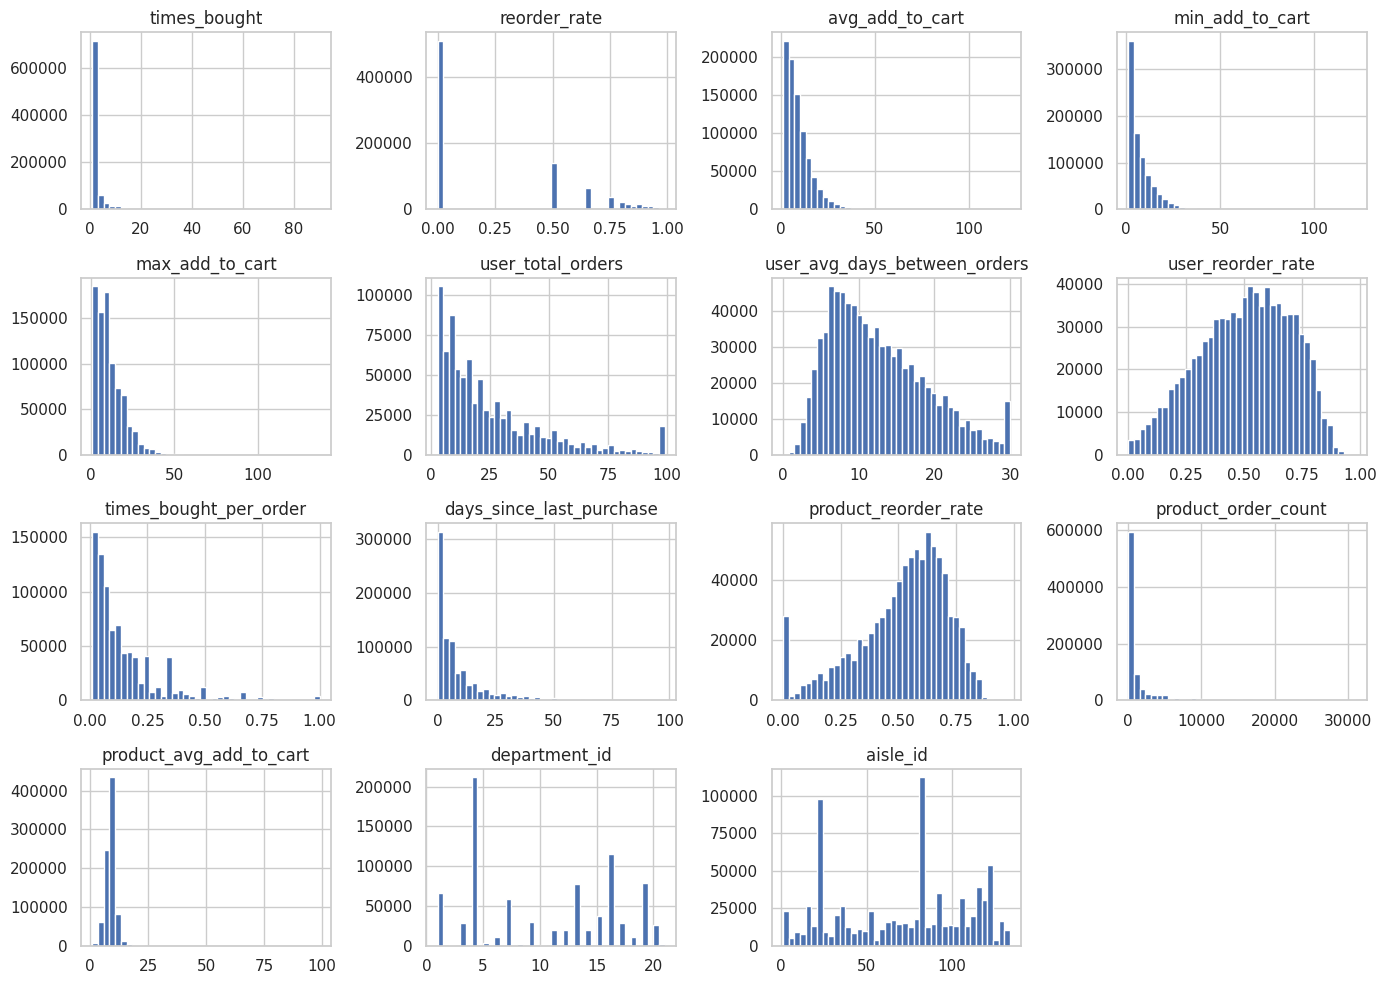

In [35]:
eda[FEATS].hist(figsize=(14, 10), bins=40)
plt.tight_layout()
plt.show()


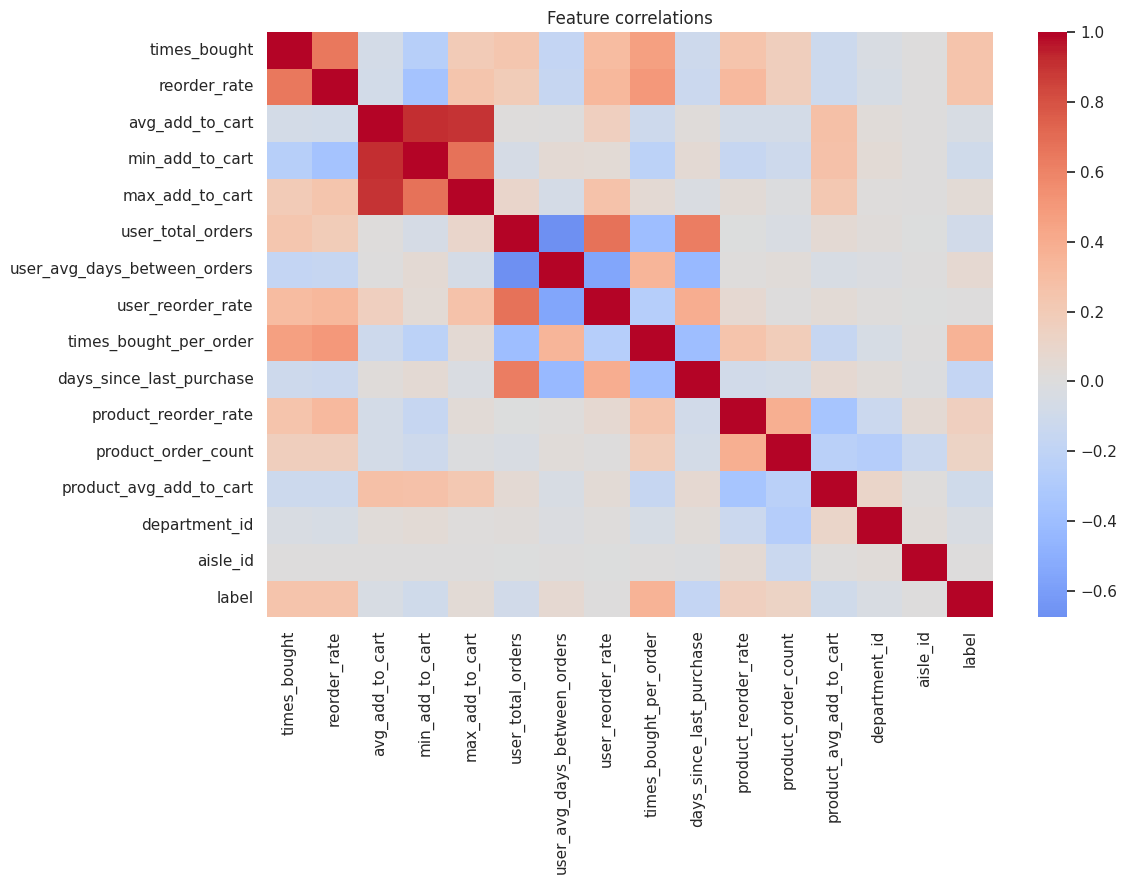

In [36]:
plt.figure(figsize=(12, 9))
sns.heatmap(eda[FEATS + ["label"]].corr(), cmap="coolwarm", center=0)
plt.title("Feature correlations")
plt.tight_layout()
plt.show()


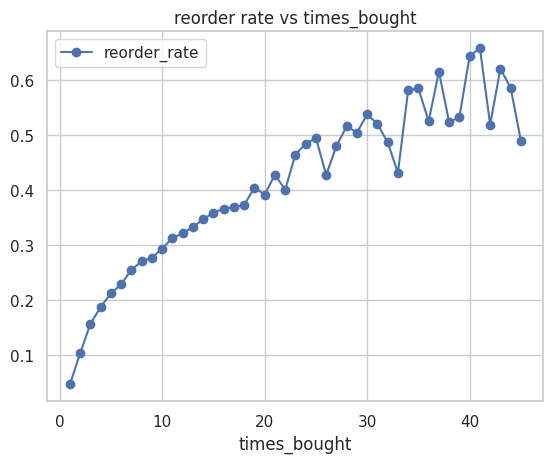

,n,reorder_rate
product_id,,
24852,4817,0.350218
13176,3980,0.330653
38689,323,0.328173
13166,126,0.317460
39180,162,0.308642
14999,111,0.306306
8571,204,0.294118
37710,160,0.293750
36011,278,0.291367


In [37]:
g = eda.groupby("times_bought").agg(n=("label","size"), reorder_rate=("label","mean")).reset_index()
g = g[g["n"] >= 50]
g.plot(x="times_bought", y="reorder_rate", marker="o", title="reorder rate vs times_bought")
plt.show()
top = (eda.groupby("product_id").agg(n=("label","size"), reorder_rate=("label","mean")).query("n >= 100").sort_values("reorder_rate", ascending=False).head(10))
top


## Advanced data science lab


### 1. Model lab - evaluate the deployed booster


In [38]:
import boto3, lightgbm as lgb
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss, roc_curve, precision_recall_curve)

local_model = "/tmp/feast_model/model.txt"
Path(local_model).parent.mkdir(parents=True, exist_ok=True)
boto3.client("s3", region_name=REGION).download_file(BUCKET, "models/instacart/latest/model.txt", local_model)
booster = lgb.Booster(model_file=local_model)
print("model loaded | trees:", booster.num_trees())

FEATS = feast_config.FEATURE_COLUMNS
test = eda[eda["user_id"] % 10 == 9].copy()
y_test = test["label"].astype(int)
test["proba"] = booster.predict(test[FEATS])
print("test rows: %d | positive rate: %.4f" % (len(test), y_test.mean()))
print("ROC-AUC : %.4f" % roc_auc_score(y_test, test["proba"]))
print("PR-AUC  : %.4f" % average_precision_score(y_test, test["proba"]))
print("logloss : %.4f" % log_loss(y_test, test["proba"]))
print("brier   : %.4f" % brier_score_loss(y_test, test["proba"]))


model loaded | trees: 66
test rows: 87151 | positive rate: 0.0947
ROC-AUC : 0.8305
PR-AUC  : 0.3980
logloss : 0.2433
brier   : 0.0697


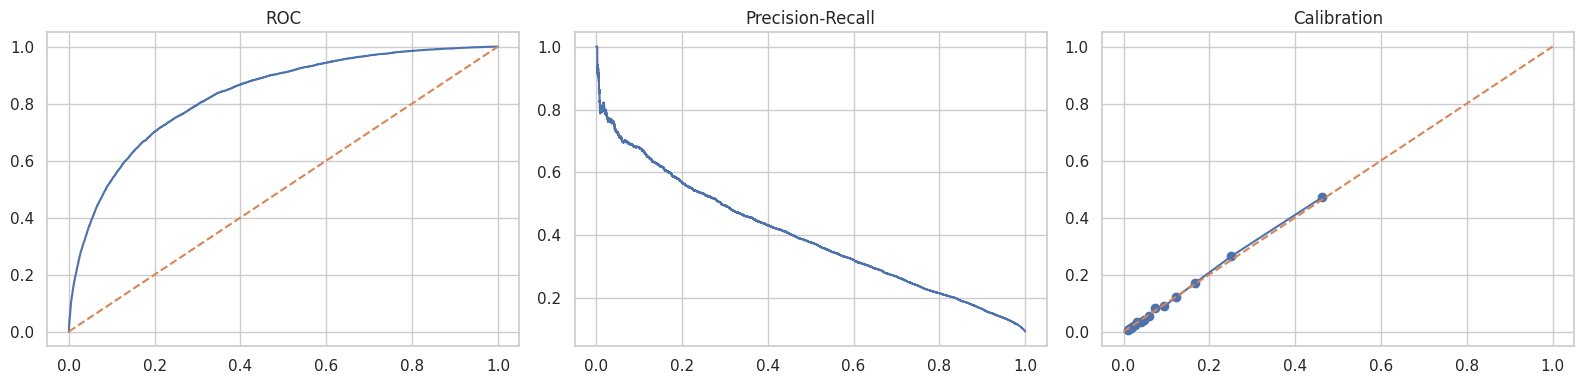

In [39]:
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
fpr, tpr, _ = roc_curve(y_test, test["proba"])
ax[0].plot(fpr, tpr); ax[0].plot([0,1],[0,1],"--"); ax[0].set_title("ROC")
prec, rec, _ = precision_recall_curve(y_test, test["proba"])
ax[1].plot(rec, prec); ax[1].set_title("Precision-Recall")
frac, mean_pred = calibration_curve(y_test, test["proba"], n_bins=15, strategy="quantile")
ax[2].plot(mean_pred, frac, marker="o"); ax[2].plot([0,1],[0,1],"--"); ax[2].set_title("Calibration")
plt.tight_layout(); plt.show()


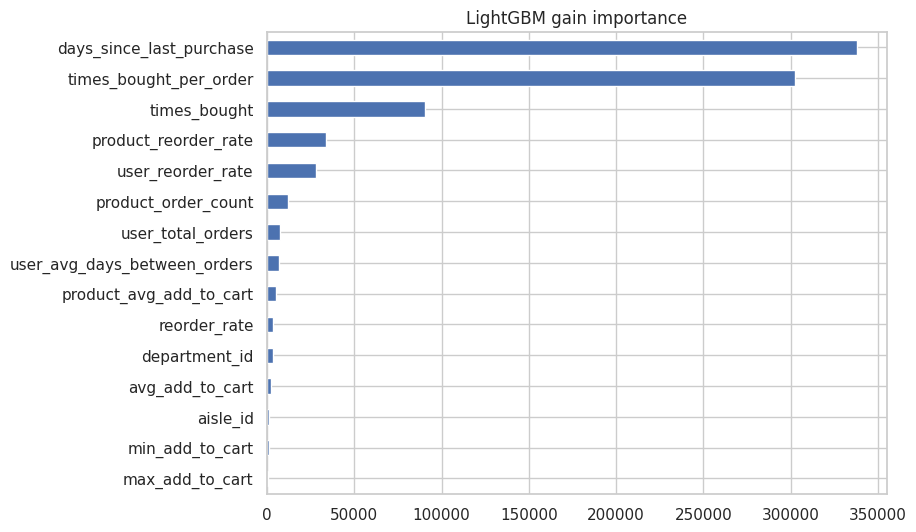

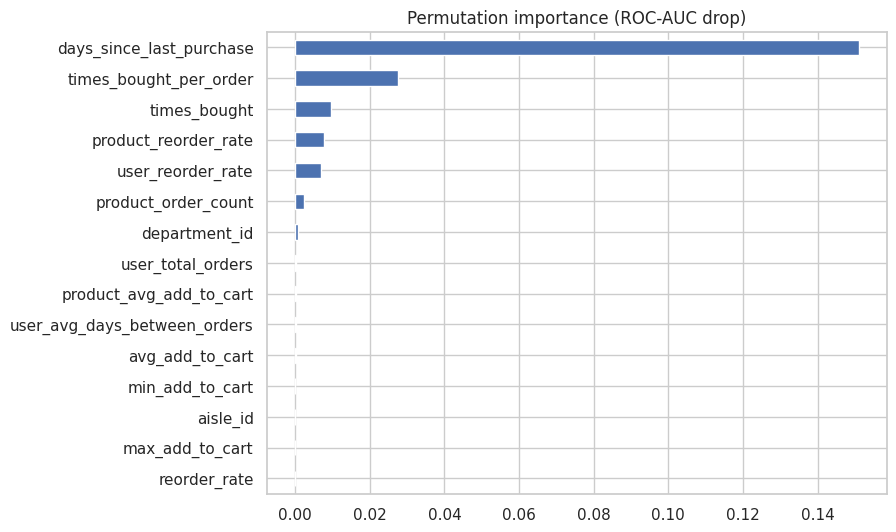

In [40]:
imp = pd.Series(booster.feature_importance(importance_type="gain"), index=FEATS).sort_values(ascending=False)
imp.plot.barh(figsize=(8,6), title="LightGBM gain importance"); plt.gca().invert_yaxis(); plt.show()

s = test.sample(min(20000, len(test)), random_state=0)
X = s[FEATS].reset_index(drop=True); y = s["label"].astype(int).reset_index(drop=True)
base = roc_auc_score(y, booster.predict(X)); rng = np.random.default_rng(0); importances = {}
for col in FEATS:
    drops = []
    for _ in range(5):
        Xp = X.copy(); Xp[col] = rng.permutation(X[col].to_numpy())
        drops.append(base - roc_auc_score(y, booster.predict(Xp)))
    importances[col] = float(np.mean(drops))
pd.Series(importances).sort_values(ascending=False).plot.barh(figsize=(8,6), title="Permutation importance (ROC-AUC drop)"); plt.gca().invert_yaxis(); plt.show()


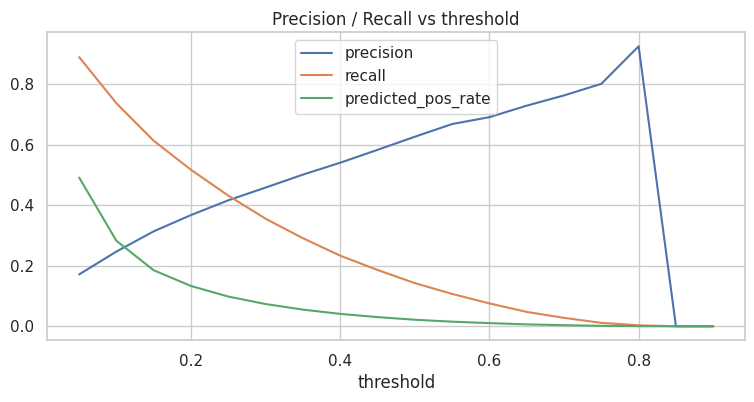

In [41]:
thr = np.linspace(0.05, 0.9, 18); rows = []
for t in thr:
    pred = (test["proba"] >= t).astype(int)
    tp = int(((pred==1)&(y_test==1)).sum()); fp = int(((pred==1)&(y_test==0)).sum()); fn = int(((pred==0)&(y_test==1)).sum())
    rows.append({"threshold": round(t,2), "precision": tp/(tp+fp) if tp+fp else 0.0, "recall": tp/(tp+fn) if tp+fn else 0.0, "predicted_pos_rate": pred.mean()})
pd.DataFrame(rows).set_index("threshold").plot(figsize=(9,4), title="Precision / Recall vs threshold"); plt.show()


### 2. Feature signal - mutual information


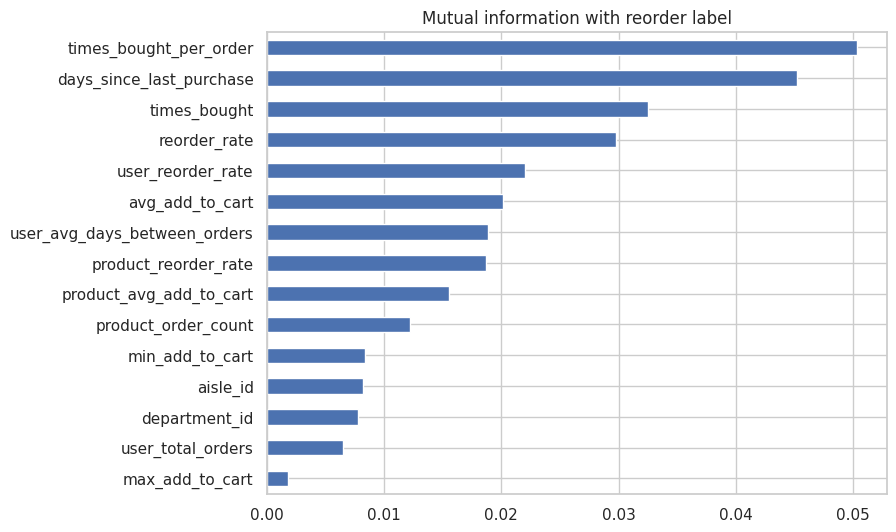

times_bought_per_order          0.050378
days_since_last_purchase        0.045225
times_bought                    0.032482
reorder_rate                    0.029783
user_reorder_rate               0.021999
avg_add_to_cart                 0.020122
user_avg_days_between_orders    0.018826
product_reorder_rate            0.018665
product_avg_add_to_cart         0.015538
product_order_count             0.012176
min_add_to_cart                 0.008398
aisle_id                        0.008153
department_id                   0.007727
user_total_orders               0.006486
max_add_to_cart                 0.001764
dtype: float64

In [42]:
from sklearn.feature_selection import mutual_info_classif
s = test.sample(min(50000, len(test)), random_state=1)
mi = pd.Series(mutual_info_classif(s[FEATS], s["label"].astype(int), random_state=0), index=FEATS).sort_values(ascending=False)
mi.plot.barh(figsize=(8,6), title="Mutual information with reorder label"); plt.gca().invert_yaxis(); plt.show()
mi


### 3. Structure - PCA & clustering


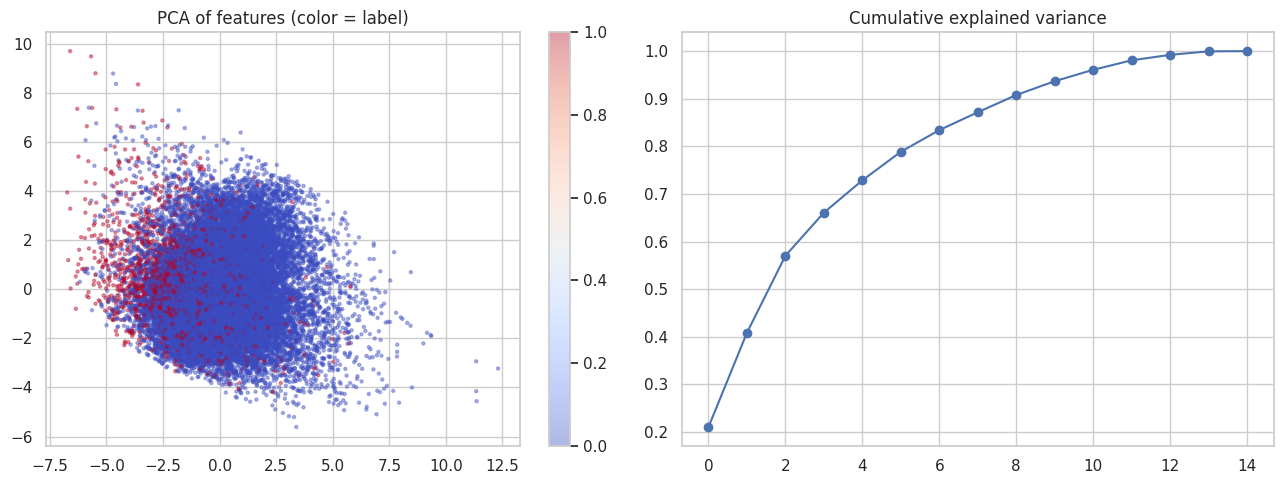

In [43]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
s = test.sample(min(30000, len(test)), random_state=2)
Xz = StandardScaler().fit_transform(s[FEATS].fillna(0))
Z = PCA(n_components=2, random_state=0).fit_transform(Xz)
pca_full = PCA().fit(Xz)
fig, ax = plt.subplots(1, 2, figsize=(13,5))
sc = ax[0].scatter(Z[:,0], Z[:,1], c=s["label"], cmap="coolwarm", s=5, alpha=0.4)
ax[0].set_title("PCA of features (color = label)"); plt.colorbar(sc, ax=ax[0])
ax[1].plot(np.cumsum(pca_full.explained_variance_ratio_), marker="o")
ax[1].set_title("Cumulative explained variance")
plt.tight_layout(); plt.show()


In [44]:
from sklearn.cluster import KMeans
km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xz)
s = s.assign(cluster=km.labels_)
prof = s.groupby("cluster")[FEATS].mean()
prof["reorder_rate"] = s.groupby("cluster")["label"].mean()
prof["size"] = s.groupby("cluster").size()
prof


,times_bought,reorder_rate,avg_add_to_cart,min_add_to_cart,max_add_to_cart,user_total_orders,user_avg_days_between_orders,user_reorder_rate,times_bought_per_order,days_since_last_purchase,product_reorder_rate,product_order_count,product_avg_add_to_cart,department_id,aisle_id,size
cluster,,,,,,,,,,,,,,,,
0,6.320405,0.240261,7.947671,3.459928,14.132143,27.297409,11.391689,0.592263,0.313696,4.132487,0.629631,1569.830566,8.186382,9.709113,74.582115,5827
1,1.218976,0.073823,6.587208,6.172052,7.007047,11.564541,16.276733,0.350650,0.154517,4.440100,0.489545,857.906555,8.645444,10.196030,71.745964,11636
2,5.441261,0.280802,6.582217,3.978510,10.548711,22.183382,13.320276,0.509529,0.306131,4.792264,0.805978,20644.939453,6.218439,4.000000,40.310886,698
3,1.587629,0.018641,7.247961,6.182884,8.414207,53.154358,6.618507,0.650063,0.033082,25.589464,0.475692,753.742554,9.033654,10.871063,70.898460,7081
4,1.309794,0.050652,21.513187,20.236654,22.905422,20.916771,13.052995,0.517780,0.104589,7.947247,0.455631,653.493713,10.172334,11.023329,70.176758,4758


### 4. Recommendation - top-N vs popularity baseline


In [45]:
def hit_rate_at_k(df, score_col, k=5):
    hits = []
    for _, g in df.groupby("user_id"):
        top = g.sort_values(score_col, ascending=False).head(k)
        hits.append(int((top["label"] == 1).any()))
    return float(np.mean(hits)) if hits else float("nan")

users = test["user_id"].drop_duplicates().sample(min(500, test["user_id"].nunique()), random_state=3)
sub = test[test["user_id"].isin(users)].copy(); sub["popularity"] = sub["product_order_count"]
print("users evaluated:", sub["user_id"].nunique())
for k in (1, 3, 5, 10):
    print("hit_rate@%-2d model=%.3f  popularity=%.3f" % (k, hit_rate_at_k(sub,"proba",k), hit_rate_at_k(sub,"popularity",k)))


users evaluated: 500
hit_rate@1  model=0.550  popularity=0.318
hit_rate@3  model=0.740  popularity=0.522
hit_rate@5  model=0.814  popularity=0.644
hit_rate@10 model=0.908  popularity=0.778


In [46]:
for uid in users.head(3):
    g = test[test.user_id == uid].sort_values("proba", ascending=False).head(5)
    print("user %s -> top-5 candidates" % uid)
    print(g[["product_id","proba","label"]].to_string(index=False)); print()


user 30689 -> top-5 candidates
 product_id    proba  label
      28204 0.672869      1
      18818 0.560786      1
      47630 0.559622      1
       8012 0.555952      0
      45007 0.545178      1

user 202949 -> top-5 candidates
 product_id    proba  label
       7862 0.428028      1
        890 0.377017      1
      14458 0.106335      0
      14715 0.092778      0
      42282 0.075436      0

user 19829 -> top-5 candidates
 product_id    proba  label
       3957 0.826537      1
      39877 0.592412      1
       2716 0.570475      1
      31683 0.531846      0
      13176 0.504786      0



### 5. Department-level reorder behavior


In [47]:
dept_path = root / "instacart_data" / "departments.csv"
if dept_path.exists():
    depts = pd.read_csv(dept_path); depts["department_id"] = depts["department_id"].astype("float32")
    d = test.merge(depts, on="department_id", how="left")
    agg = d.groupby("department").agg(candidates=("label","size"), reorder_rate=("label","mean")).sort_values("reorder_rate", ascending=False)
else:
    agg = test.groupby("department_id").agg(candidates=("label","size"), reorder_rate=("label","mean")).sort_values("reorder_rate", ascending=False)
agg.head(15)


,candidates,reorder_rate
department,,
pets,342,0.134503
beverages,5898,0.129027
produce,21170,0.128862
dairy eggs,11572,0.119772
missing,287,0.111498
bakery,2979,0.107754
meat seafood,2010,0.103980
deli,2715,0.089503
frozen,6825,0.082344


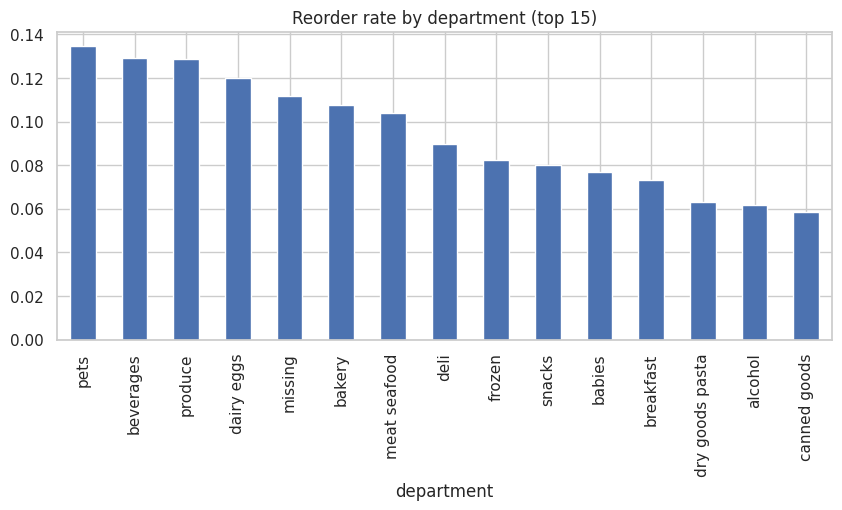

In [48]:
agg["reorder_rate"].head(15).plot.bar(figsize=(10,4), title="Reorder rate by department (top 15)"); plt.show()


### 6. Online/offline consistency & freshness


In [49]:
sample_pairs = test[["user_id","product_id"]].drop_duplicates().head(200).to_dict("records")
off = test.set_index(["user_id","product_id"]).loc[[(p["user_id"], p["product_id"]) for p in sample_pairs], FEATS]
try:
    resp = store.get_online_features(features=feast_cols, entity_rows=sample_pairs)
    onl = resp.to_df() if hasattr(resp, "to_df") else pd.DataFrame(resp.to_dict())
    onl = onl.set_index(["user_id","product_id"])[FEATS]
    diff = (onl.fillna(0) - off.fillna(0)).abs()
    print("pairs checked      :", len(sample_pairs))
    print("missing online     :", int(onl.isnull().any(axis=1).sum()))
    print("max abs difference :", float(diff.max().max()))
    print("all match (<=1e-6) :", bool((diff <= 1e-6).all().all()))
except Exception as exc:
    print("WARNING: consistency check skipped (is the tunnel up?):", exc)


pairs checked      : 200
missing online     : 0
max abs difference : 0.0
all match (<=1e-6) : True


### 7. Data quality checks


In [50]:
checks = {
    "no missing values": not test[FEATS + ["label"]].isnull().any().any(),
    "label in {0,1}": set(test["label"].unique()) <= {0, 1},
    "reorder_rate in [0,1]": bool(test["reorder_rate"].between(0, 1).all()),
    "times_bought >= 1": bool((test["times_bought"] >= 1).all()),
    "no duplicate (user, product)": not test.duplicated(["user_id","product_id"]).any(),
    "event_timestamp present": bool(test["event_timestamp"].notna().all()),
    "reorder_rate correlates with label (>0.2)": float(test["reorder_rate"].corr(test["label"])) > 0.2,
}
for name, ok in checks.items():
    print(("PASS" if ok else "FAIL"), "-", name)


PASS - no missing values
PASS - label in {0,1}
PASS - reorder_rate in [0,1]
PASS - times_bought >= 1
PASS - no duplicate (user, product)
PASS - event_timestamp present
PASS - reorder_rate correlates with label (>0.2)
